---
title: "Chapter 17: Introduction to Computer Vision"
---


::: {.callout-lo}

## Learning outcomes {.unnumbered}

By the end of this chapter, you should be able to:

- Explain how a neural network computes predictions using learned features and nonlinear activations.
- Describe how images are represented numerically and why CNNs use local, shared filters.
- Use a pretrained image classifier and recognize the limitations of its output labels.
- Extract frozen pretrained features and train logistic regression for new labels.
- Evaluate an image classifier with appropriate preprocessing, data splits, and error analysis.

:::

Images contain information that is difficult to express as a short list of hand-designed features. Consider the cats below. They have different coat colours, patterns, and lengths of fur, and appear in different poses, settings, and lighting. Some are sleeping; others are playing or grooming. Despite these differences, every image has the same label: **cat**. An effective classifier needs to recognize features that distinguish cats from other categories while tolerating variation within the cat category.

![Cats with different coat colours, patterns, and lengths of fur, shown sleeping, grooming, playing, and resting in indoor and outdoor settings. Despite differences in appearance, pose, viewpoint, and background, all share the label cat.](img/cat-variations.png)

Images from the same class can therefore have very different pixel arrays. Which differences matter depends on the task: coat colour does not change the label **cat**, but it would matter if our task were to classify coat colours.

In this chapter, we will build a classifier for seven food categories using only a few hundred labelled images. That is far too little data to train a large vision model from scratch. Our practical solution will be **transfer learning**: we will reuse a **representation**—a set of numerical features describing an image—learned from a much larger image collection and adapt it to our task.

**Imports**


In [30]:
#| code-fold: true
#| code-summary: "Show imports and setup"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models

torch.manual_seed(42)
np.random.seed(42)
plt.rcParams["font.size"] = 14
pd.set_option("display.max_colwidth", 120)

DATA_DIR = Path("data")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE


device(type='cpu')

## From linear models to neural networks

Recall that a linear model combines input features using learned weights and an intercept. In binary logistic regression, we then apply sigmoid to turn the resulting score into the predicted probability of the positive class. The diagram below draws these familiar operations as a network.

![Binary logistic regression drawn as a network: four input features contribute to a weighted sum plus an intercept, followed by sigmoid to produce a probability and thresholding to produce the predicted label.](img/lr-graphical.png)

Read the diagram from left to right. Each connection multiplies an input $x_j$ by its weight $w_j$. The $\Sigma$ symbol collects these contributions and adds $b$, giving the score $z$. The **bias** $b$ is another name for the intercept. Sigmoid gives the predicted probability $\hat p$ of the positive class. Applying a threshold gives the predicted label $\hat y$. For example, with a threshold of 0.5, we predict 1 when $\hat p \geq 0.5$, and 0 otherwise.

This is a graphical representation of our familiar logistic-regression model. Its decision boundary is still linear, so it has the same limitations as before. Imagine a two-feature classification problem in which one class occupies a small circle and the other surrounds it. A straight decision boundary cannot separate these classes. We have already encountered models that can capture nonlinear relationships. How could we extend the weighted-sum idea to do this?

A **neural network** introduces intermediate computations called **hidden layers**. Each unit in a hidden layer computes its own weighted sum and intercept, then applies a nonlinear **activation function**. The next diagram shows four inputs feeding three hidden units, whose outputs are combined to make a binary classification prediction.

![A neural network with four inputs, three hidden units using sigmoid activations, and one output unit. The final sigmoid produces a probability, and thresholding converts it to a predicted label.](img/nn-1-hidden.png)

Each hidden unit receives the same four input features but has its own weights and bias, so it can compute a different transformation. Its sigmoid output becomes a new feature for the output unit. The output unit combines these three features using another weighted sum and bias, then applies sigmoid to produce a probability. As in logistic regression, we threshold this final probability to obtain a predicted label; we do not threshold the hidden features.

The activation boxes show steps within each unit, not extra hidden units. The labels $W^{(1)}$ and $W^{(2)}$ collect the weights used at the hidden and output layers. Superscripts identify layers, not powers.

Let us write out these computations for one example. For the first hidden unit, we first compute a score:

$$
z_1^{(1)} = w_{11}^{(1)}x_1 + w_{12}^{(1)}x_2
          + w_{13}^{(1)}x_3 + w_{14}^{(1)}x_4 + b_1^{(1)}.
$$

For example, $w_{12}^{(1)}$ connects input 2 to hidden unit 1 in layer $(1)$. Each hidden unit has its own weights and bias.

We then apply sigmoid to obtain the first hidden feature:

$$
h_1 = \operatorname{sigmoid}\!\left(z_1^{(1)}\right).
$$

The other two hidden units repeat these steps with their own weights and biases, producing $h_2$ and $h_3$. For this network, the four original input features have now been transformed into three hidden features.

Next, the output unit combines those hidden features:

$$
z^{(2)} = w_1^{(2)}h_1 + w_2^{(2)}h_2 + w_3^{(2)}h_3 + b^{(2)}.
$$

The weights $w_j^{(2)}$ connect the hidden features to the output unit. Finally,

$$
\hat p = \operatorname{sigmoid}\!\left(z^{(2)}\right).
$$

This is the probability $\hat p$ shown before the threshold box. With a threshold of 0.5, the final decision is:

$$
\hat y = \begin{cases}1 & \text{if } \hat p \geq 0.5,\\ 0 & \text{otherwise.}\end{cases}
$$


Computing the hidden features and then the prediction is called a **forward pass**. It uses the current weights and biases without changing them. When training the whole network, we adjust weights in both the hidden and output layers so that the hidden features help predict the target. Hidden activations are features, not class probabilities, even when sigmoid puts them between zero and one.

The nonlinear activation matters. Stacking weighted sums without nonlinear activations still gives a single weighted sum and intercept. Hidden activations allow a network to produce nonlinear decision boundaries. They play a different role from the final sigmoid, which converts a binary classification score into a probability.

We used sigmoid in the hidden layer to build on a familiar function, but other nonlinear activations are also used. For example, the rectified linear unit (**ReLU**) returns zero for negative inputs and leaves positive inputs unchanged: $\operatorname{ReLU}(z)=\max(0,z)$. A network need not use the same activation in its hidden layers as at its output.

Networks can contain several hidden layers, each transforming the representation from the previous layer. This is the idea behind **deep learning**. We will use such a network to produce image features, rather than design its layers ourselves.

### How does a network learn its weights?

The supervised-learning workflow is unchanged: use examples with known targets to fit a model, then predict targets for new examples.

![The supervised-learning training workflow.](img/supervised-learning-training.png)

A **loss function** measures disagreement between predictions and known targets. Training repeatedly makes predictions and adjusts weights to reduce this loss. As with other flexible models, reducing training error does not guarantee better performance on new data.

In our worked example, the CNN has already been trained on another dataset. We will keep its weights fixed and train logistic regression on the features it produces.

## Introduction to computer vision

**Computer vision** extracts useful information from images and video. Different tasks ask for different outputs.

![Computer-vision tasks: classification gives an image label; localization adds a box; object detection labels and boxes individual objects; instance segmentation identifies each object's pixels.](img/vision-apps.jpeg)

From left to right, the figure shows an image label, a label with a bounding box, boxes around individual objects, and the pixels belonging to each object. Classification can also label images containing several objects; it simply does not locate them. Here, we focus on **image classification**: predicting a category for an entire image.

### Images as numerical arrays

A grayscale image can be represented as a height-by-width array, with one intensity value per pixel. A colour image adds a third dimension: height $\times$ width $\times$ colour channels. In an RGB image, each pixel has a red, green, and blue value. Let us inspect one of the images used later in the chapter.

Image shape: (446, 512, 3)
A 3 x 3 patch of RGB values:


array([[[112,  60,  13],
        [113,  61,  14],
        [115,  63,  16]],

       [[111,  59,  12],
        [113,  61,  14],
        [115,  63,  16]],

       [[113,  61,  14],
        [115,  63,  16],
        [117,  65,  18]]], dtype=uint8)

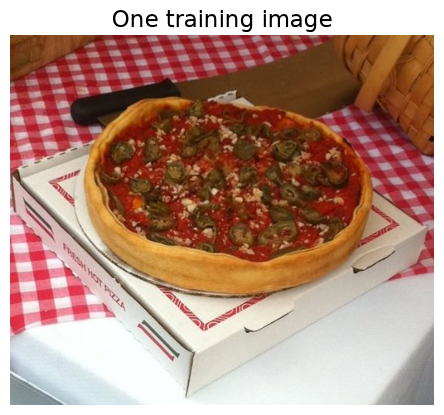

In [31]:
sample_path = next((DATA_DIR / "food-transfer-learning" / "train" / "pizza").glob("*.jpg"))
sample_image = Image.open(sample_path).convert("RGB")
sample_array = np.asarray(sample_image)

print(f"Image shape: {sample_array.shape}")
print("A 3 x 3 patch of RGB values:")
display(sample_array[:3, :3, :])

plt.imshow(sample_image)
plt.title("One training image")
plt.axis("off");


We could flatten the array into one long feature vector and pass it to a model from an earlier chapter. However, a $200 \times 200$ RGB image already has $200 \times 200 \times 3 = 120{,}000$ pixel values. Flattening preserves these values, but an ordinary classifier does not automatically use the fact that nearby pixels form local patterns. Moving an object slightly can also change many feature values.

Raw pixels can therefore be a difficult starting point for the familiar classifiers used here. Instead, we will use a neural network to transform each image into a smaller set of learned features, then fit logistic regression to those features.

### Convolutions: why do they help with images?

In the network above, every input connects to every hidden unit. This is called a **fully connected layer**. Applying that approach directly to images would connect every pixel value to every hidden unit. This creates many parameters and does not encode the fact that nearby pixels form local patterns.

A **convolution** applies a small array of weights called a **filter** or **kernel** across an image. At each position, it computes a weighted sum of the local pixel values. The resulting array is called a **feature map**. A learned filter can produce large responses to a local pattern such as an edge. The same filter is used at every location, so an edge detector learned in the upper-left corner can also detect a similar edge elsewhere.

![An animation illustrating a small filter moving across an input array to produce an output feature map.](img/cnn-5.gif)

You can also experiment with hand-designed filters in the interactive [Image Kernels explainer](https://setosa.io/ev/image-kernels/). In a neural network, the filter weights are learned from training data rather than chosen by hand.

::: {.callout-note title="Recognizing patterns in different locations"}

A shared filter can recognize a pattern in different locations, but changes in viewpoint, size, or lighting can still cause mistakes.

:::

### Convolutional neural networks

A **convolutional neural network** (CNN) combines convolutions and nonlinear activations to turn an image into a prediction.

![A simplified CNN: convolutions, ReLU, and pooling produce features that fully connected layers use for binary cat classification. This is not the exact architecture used later.](img/cnn_big_picture.png)

*Image source: [Google Developers: Machine Learning](https://developers.google.com/machine-learning).*

Each convolutional layer produces several feature maps. ReLU introduces nonlinearity, while **pooling** reduces their height and width. The max-pooling operations shown keep the largest response in each small region. Early layers often respond to edges and colour changes; later layers combine responses into more complex patterns.

The network has a **feature extractor**, which builds an image representation, and a **classification head**, which maps it to class scores. The figure illustrates “cat or not cat”; our pretrained model has a different architecture and predicts 1,000 categories.

## Pretrained models

### What are pretrained models in computer vision?

A **pretrained model** supplies weights already learned on another dataset. Training a CNN can require substantial labelled data and computation; using pretrained weights lets us start making predictions immediately. Creating the same network without its learned weights would not give useful predictions.

#### ImageNet and multiclass classification

ImageNet is a large collection of labelled images. Our pretrained CNN was trained on its 1,000-category image-classification task. It produces one score per category and predicts the class with the largest score. Unlike the binary examples above, we select the class with the largest score (or softmax probability) rather than thresholding a single probability. It cannot invent new output labels.

This is **multiclass classification**: each image receives one label from several possible classes. Our seven-category food task has the same structure. It differs from multilabel classification, where an image can receive several labels at once.

#### From scores to probabilities with softmax

**Softmax** converts class scores into probabilities that sum to one. The largest score receives the largest probability. In the example below, the class labels are numbered 0–3. A high probability still does not guarantee a correct or useful prediction, as we will see below.

::: {.callout-note collapse="true" title="Optional: the softmax formula"}

For class scores $z_1,\ldots,z_K$,

$$
P(y=k) = \frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}}.
$$

Exponentiation makes the values positive, and division by their sum makes them add to one.

:::

In [32]:
scores = torch.tensor([1.2, -0.4, 2.0, 0.7])
probabilities = torch.softmax(scores, dim=0)
pd.DataFrame(
    {"score": scores.numpy(), "softmax probability": probabilities.numpy()},
    index=["class 0", "class 1", "class 2", "class 3"],
)


,score,softmax probability
class 0,1.2,0.247895
class 1,-0.4,0.050049
class 2,2.0,0.551700
class 3,0.7,0.150356


The predicted class is class 2 because it has the highest score and, consequently, the highest softmax probability. Notice that every probability depends on all four scores. Increasing the score for one class reduces the probability available to the others.


### Using pretrained models out of the box

`torchvision.models` provides different CNNs and their pretrained weights. We will use MobileNet V3 Small, a relatively lightweight ImageNet model. The weight object supplies its category names and, through `weights.transforms()`, the preprocessing it expects: resizing and cropping images and rescaling their colour values. The plots below show the original photographs; the CNN receives their preprocessed versions. The first call may download the weights.

The code puts the model in prediction mode with `eval()` and uses `torch.inference_mode()` for efficient prediction. We will reuse this setup without needing to study its internal details.

In [33]:
#| code-fold: true
#| code-summary: "Show model setup and plotting helper"

weights = models.MobileNet_V3_Small_Weights.DEFAULT
imagenet_model = models.mobilenet_v3_small(weights=weights).eval()
imagenet_labels = weights.meta["categories"]
imagenet_preprocess = weights.transforms()


def show_imagenet_predictions(image_paths):
    """Show each image alongside its three highest-probability ImageNet labels."""
    ncols = min(2, len(image_paths))
    nrows = (len(image_paths) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False)
    rows = []
    for ax, image_path in zip(axes.flat, image_paths):
        image = Image.open(image_path).convert("RGB")
        # Add a batch dimension: the model expects a batch, even for one image.
        inputs = imagenet_preprocess(image).unsqueeze(0)
        with torch.inference_mode():
            scores = imagenet_model(inputs)
            probabilities, indices = torch.softmax(scores, dim=1)[0].topk(3)
        labels = [imagenet_labels[index] for index in indices.tolist()]
        ax.imshow(image)
        ax.set_title(image_path.name)
        ax.axis("off")
        ax.text(0.5, -0.04, "\n".join(
            f"{label}: {probability:.1%}"
            for label, probability in zip(labels, probabilities.tolist())
        ), transform=ax.transAxes, ha="center", va="top")
        rows.append({"image": image_path.name, "top label": labels[0],
                     "probability": probabilities[0].item()})
    for ax in axes.flat[len(image_paths):]:
        ax.axis("off")
    plt.tight_layout(h_pad=5)
    plt.show()
    return pd.DataFrame(rows)

#### When the original labels are useful

Inspect the animal photographs from `data/test_images`. Before running the cell, predict the labels you expect. The plots show the three highest-probability ImageNet categories for each image.

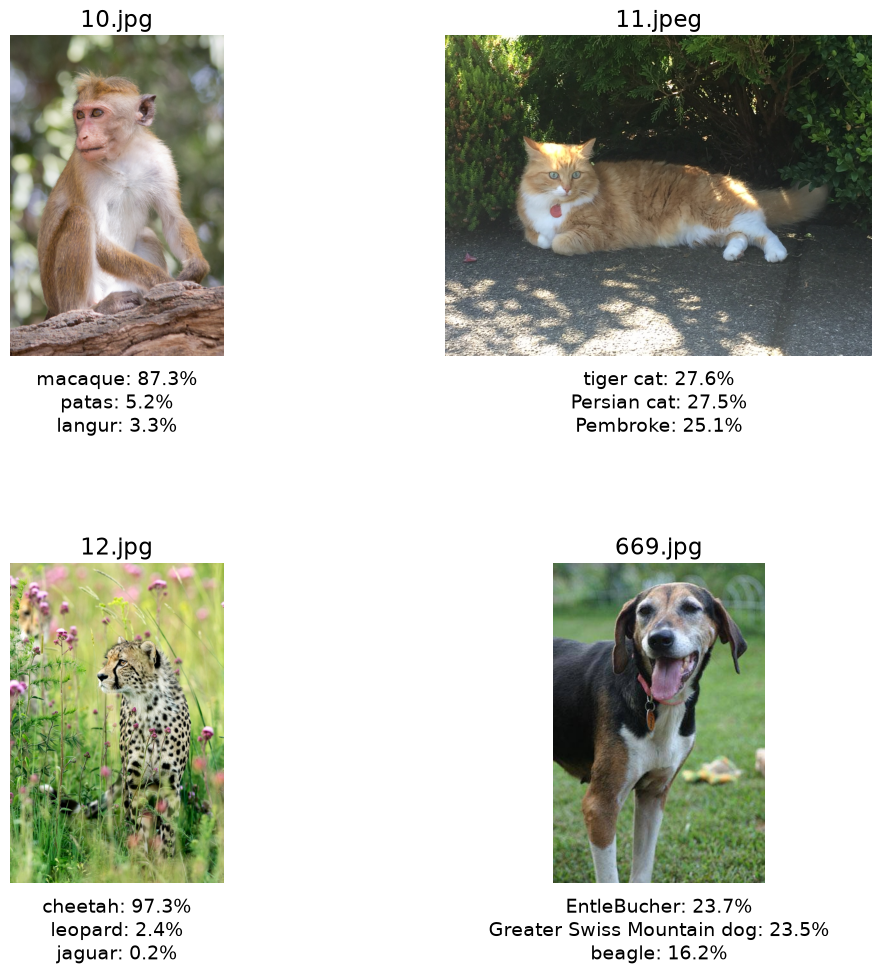

In [34]:
animal_paths = sorted(
    path for path in (DATA_DIR / "test_images").iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)
animal_results = show_imagenet_predictions(animal_paths)

The model identifies a *macaque* and *cheetah* with high confidence, without any additional training on these photographs. Other predictions are less decisive: several cat or dog categories receive similar probabilities. Recognizing an animal and identifying its exact category are different levels of success.

#### When the predictions do not answer our question

Now suppose we want to identify UBC landmarks. Inspect all the images in `data/UBC_img`, which also includes an apple photograph. Which predictions describe something visible, and which identify the landmark?

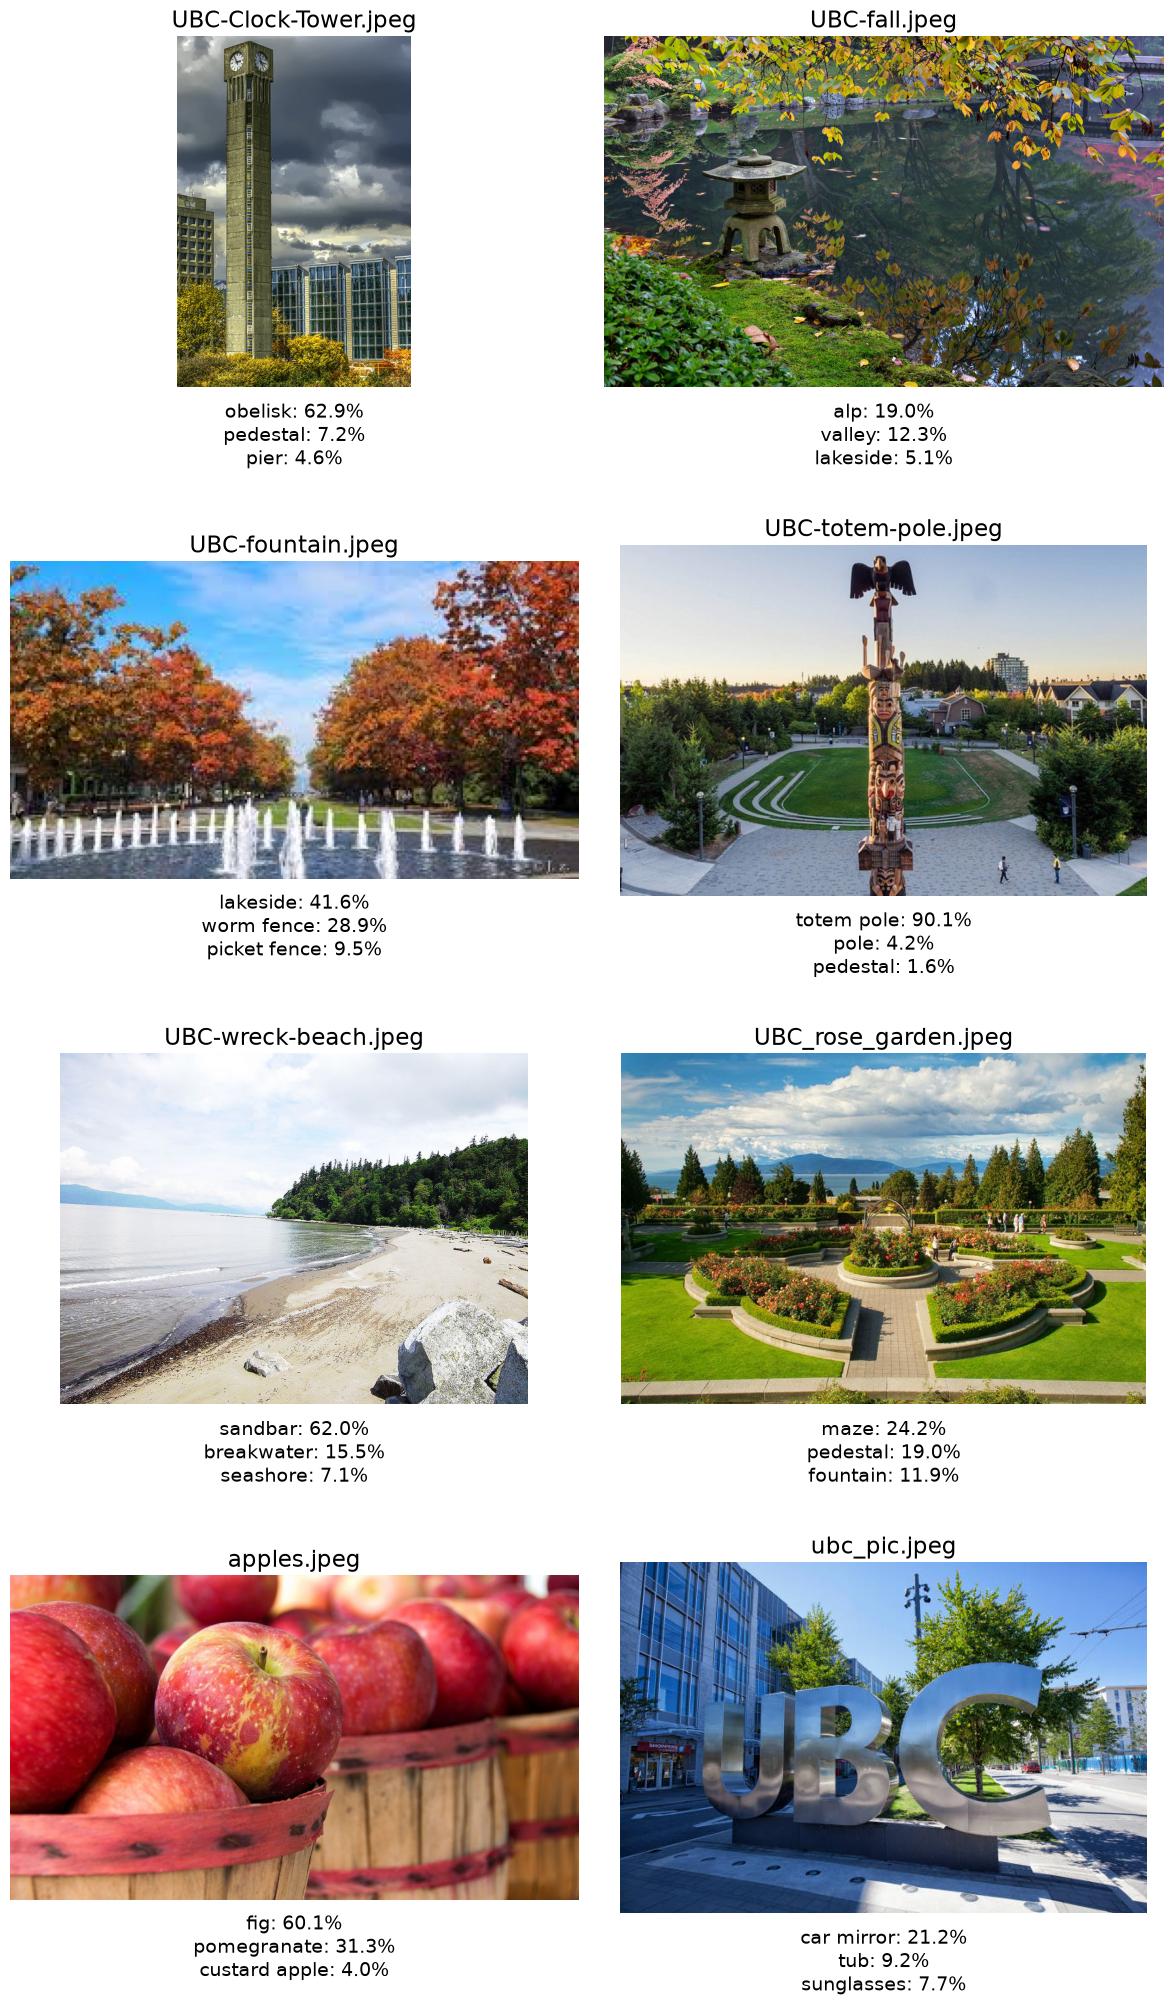

In [35]:
campus_paths = sorted(
    path for path in (DATA_DIR / "UBC_img").iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)
campus_results = show_imagenet_predictions(campus_paths)

The clock tower receives *obelisk*, and the fountain scene receives *lakeside*. The model correctly recognizes a *totem pole*, but that does not identify a particular UBC location.

The large UBC letters receive the surprising label *car mirror*, at about 21%. Their reflective shapes may explain the association, but that is a hypothesis, not something the prediction proves. The apple photograph is also misclassified as *fig*.

There are two issues here: predictions can be wrong, and our desired landmark labels are absent from ImageNet's vocabulary. Even a correct general object label may not answer our question. Could we keep the useful image features and train a classifier for our own labels?

### Transfer learning with frozen features

**Transfer learning** reuses what a model learned on one task for another. To learn landmark labels, we would need labelled landmark images. We will demonstrate the same approach using our labelled food dataset: keep the pretrained CNN's feature extractor fixed and replace its original classifier with logistic regression for our seven food labels:

$$
\text{image} \longrightarrow \text{pretrained feature extractor}
\longrightarrow \text{feature vector} \longrightarrow \text{logistic regression}.
$$

**Frozen** means that the CNN weights remain unchanged; different images still produce different feature vectors. The CNN weights were learned from ImageNet. Only the scaler and logistic regression will learn from our training images. Our labels need not appear in ImageNet's vocabulary.

#### The food dataset

Our small subset of Food-101 is organized into `train` and `valid` directories, with one subdirectory per food category. `ImageFolder` reads these directory names as labels and assigns integer identifiers. The mapping must agree across splits; the assertion below checks this.

Inspect examples and class counts before fitting a model. Keep duplicates and photographs of the same meal together when making splits. This example uses training and validation sets; for a final evaluation, reserve a separate test set.

In [36]:
food_dir = DATA_DIR / "food-transfer-learning"
food_train = datasets.ImageFolder(food_dir / "train")
food_valid = datasets.ImageFolder(food_dir / "valid")

assert food_train.class_to_idx == food_valid.class_to_idx
display(pd.DataFrame({
    "training images": pd.Series(food_train.targets).value_counts(),
    "validation images": pd.Series(food_valid.targets).value_counts(),
}).rename(index=dict(enumerate(food_train.classes))).sort_index())


,training images,validation images
beet_salad,40,10
chocolate_cake,38,9
edamame,40,10
french_fries,40,10
pizza,43,10
spring_rolls,41,9
sushi,41,9


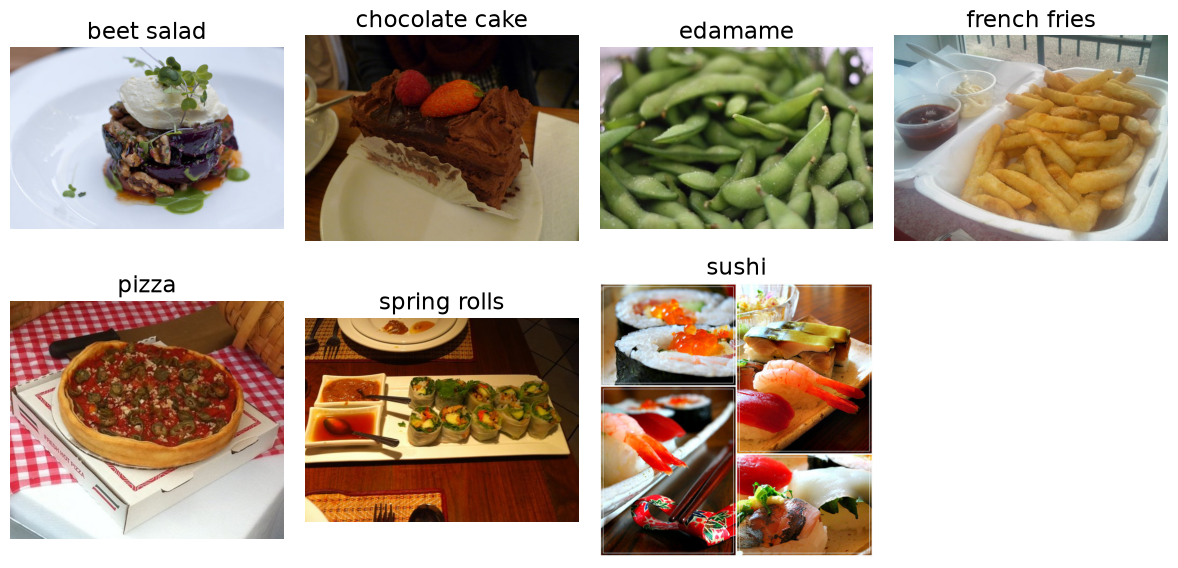

In [37]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, class_name in zip(axes.flat, food_train.classes):
    class_index = food_train.class_to_idx[class_name]
    image_index = food_train.targets.index(class_index)
    image, _ = food_train[image_index]
    ax.imshow(image)
    ax.set_title(class_name.replace("_", " "))
    ax.axis("off")
axes.flat[-1].axis("off")
plt.tight_layout()


#### Preprocessing the images

We apply the same fixed resizing, cropping, and colour-value transformations to training, validation, and new images. A `DataLoader` reads images in small batches so we do not need to hold all processed images in memory at once.

In [38]:
feature_datasets = {
    split: datasets.ImageFolder(food_dir / split, transform=imagenet_preprocess)
    for split in ["train", "valid"]
}
feature_loaders = {
    "train": DataLoader(feature_datasets["train"], batch_size=32, shuffle=False),
    "valid": DataLoader(feature_datasets["valid"], batch_size=32, shuffle=False),
}
class_names = feature_datasets["train"].classes


#### Extracting features

We use the pretrained CNN to turn each image into a feature vector instead of producing ImageNet predictions. The helper below performs this step without changing the CNN's weights. You can reuse it for your own dataset. It returns one feature row and the corresponding label for each image.

In [39]:
#| code-fold: true
#| code-summary: "Show frozen feature-extraction helper"

feature_model = models.mobilenet_v3_small(weights=weights)
feature_model.classifier = nn.Identity()
feature_model.requires_grad_(False)
feature_model = feature_model.to(DEVICE).eval()


def extract_features(model, data_loader, device):
    """Return one feature row and one target for each image."""
    feature_batches = []
    target_batches = []

    with torch.inference_mode():
        for images, targets in data_loader:
            feature_batches.append(model(images.to(device)).cpu())
            target_batches.append(targets)

    return (
        torch.cat(feature_batches).numpy(),
        torch.cat(target_batches).numpy(),
    )

In [40]:
Z_train, y_train = extract_features(feature_model, feature_loaders["train"], DEVICE)
Z_valid, y_valid = extract_features(feature_model, feature_loaders["valid"], DEVICE)

print(f"Training feature matrix: {Z_train.shape}")
print(f"Validation feature matrix: {Z_valid.shape}")


Training feature matrix: (283, 576)
Validation feature matrix: (67, 576)


`Z_train` contains one row per training image and one column per extracted feature; `y_train` contains the corresponding labels. Each row has 576 features because that is the output size of this particular extractor, not a number we choose.

These are learned features like the hidden outputs in our earlier network, but produced by a larger CNN. We can pass this ordinary feature matrix to scikit-learn. Applying the fixed extractor to validation images does not learn from them; fitting the scaler and classifier does, so they must use only training features.

We can reuse these matrices when trying different logistic-regression settings. Changing the extractor or image preprocessing requires extracting features again.

#### Training and comparing classifiers

A most-frequent `DummyClassifier` provides a reference score, near one seventh for these roughly balanced classes. Our pipeline then fits a scaler and logistic regression on training features only. Validation examples use the already fitted pipeline.

In [41]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(Z_train, y_train)

feature_pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=42),
)
feature_pipe.fit(Z_train, y_train)

pd.DataFrame(
    {
        "training accuracy": [dummy.score(Z_train, y_train), feature_pipe.score(Z_train, y_train)],
        "validation accuracy": [dummy.score(Z_valid, y_valid), feature_pipe.score(Z_valid, y_valid)],
    },
    index=["most-frequent baseline", "pretrained features + logistic regression"],
)


,training accuracy,validation accuracy
most-frequent baseline,0.151943,0.149254
pretrained features + logistic regression,1.000000,0.865672


Compare validation accuracy with the dummy baseline to assess whether the learned features help distinguish food categories. Also compare training and validation accuracy: a large gap can indicate overfitting. Because the validation set is small, avoid treating small score differences as decisive.

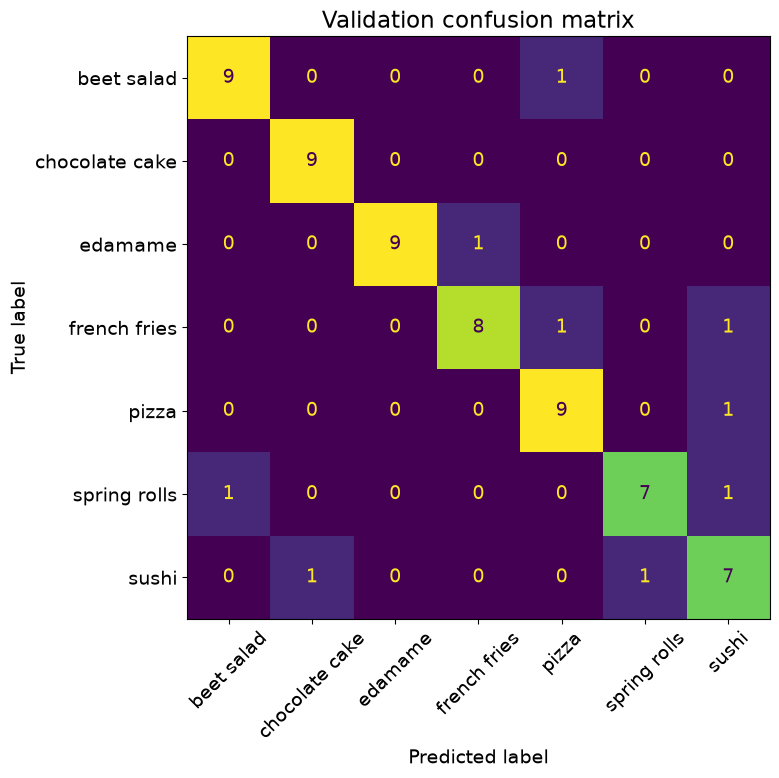

In [42]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_estimator(
    feature_pipe,
    Z_valid,
    y_valid,
    display_labels=[name.replace("_", " ") for name in class_names],
    xticks_rotation=45,
    ax=ax,
    colorbar=False,
)
ax.set_title("Validation confusion matrix")
plt.tight_layout()


The confusion matrix shows which categories are confused. Inspect individual mistakes too: they may reveal visual similarity, ambiguous labels, or unrepresentative images. The unshuffled validation loader keeps feature rows in the same order as the original images.

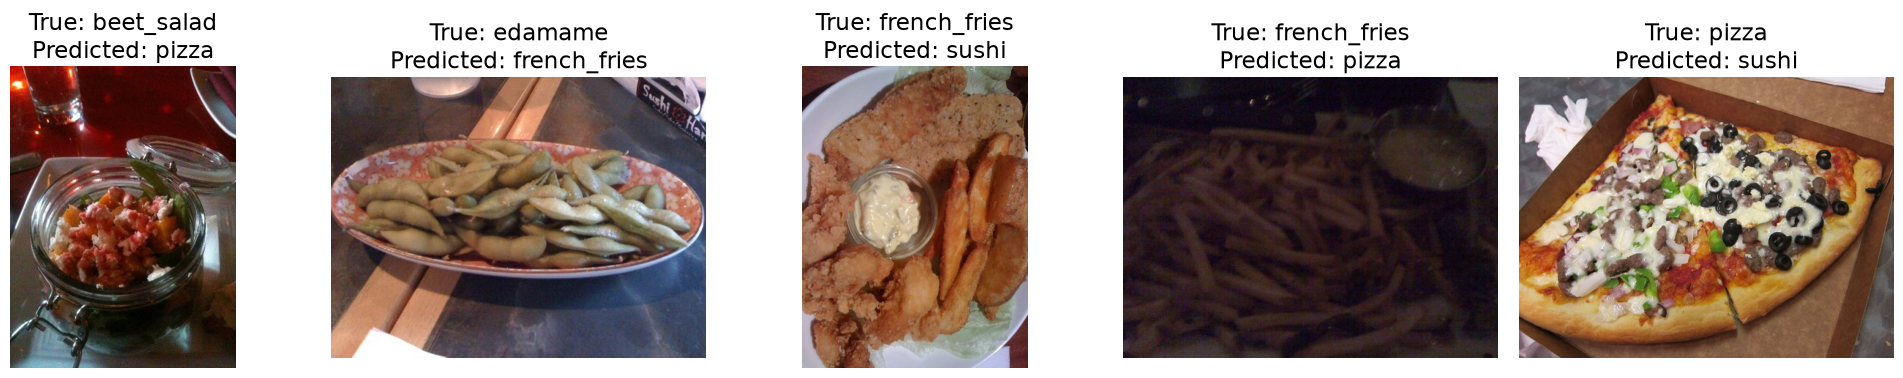

In [43]:
#| code-fold: true
#| code-summary: "Show individual validation mistakes"

valid_predictions = feature_pipe.predict(Z_valid)
error_indices = np.flatnonzero(valid_predictions != y_valid)[:5]
if len(error_indices):
    fig, axes = plt.subplots(1, len(error_indices), figsize=(4 * len(error_indices), 4), squeeze=False)
    for ax, index in zip(axes.flat, error_indices):
        image_path, _ = food_valid.samples[index]
        ax.imshow(Image.open(image_path).convert("RGB"))
        ax.set_title(f"True: {class_names[y_valid[index]]}\nPredicted: {class_names[valid_predictions[index]]}")
        ax.axis("off")
    plt.tight_layout()
else:
    print("No validation mistakes; a small validation set still leaves uncertainty.")


#### Predicting labels for new images

Prediction must repeat the same image preprocessing and frozen feature extraction, then use the already fitted pipeline. Do not fit a new scaler or classifier to the incoming image. The helper below accepts a file path and returns one of our food labels, rather than an ImageNet label.

In [44]:
def predict_food(image_path):
    image = Image.open(image_path).convert("RGB")
    inputs = imagenet_preprocess(image).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        features = feature_model(inputs).cpu().numpy()
    label_index = int(feature_pipe.predict(features)[0])
    return class_names[label_index]


# Demonstrate on a held-out validation image; replace this path for a new photo.
example_path, true_index = food_valid.samples[0]
print("True label:", class_names[true_index])
print("Predicted label:", predict_food(example_path))

True label: beet_salad
Predicted label: beet_salad


The integer prediction refers to the label mapping checked earlier. The model always selects a known food category, even if we supply an unrelated image. A prediction alone is not evidence that an image belongs to one of those categories.

### Practical considerations and limitations

**Transfer depends on the images.** A representation learned from everyday photographs may work poorly on satellite images, sketches, or medical images. This difference between training conditions and use is called **domain shift**. Pretrained features can also inherit biases and gaps from their source data, so evaluate on images representative of the intended use.

**Consider computational cost.** A larger feature extractor may improve accuracy but need more time and memory. Start with a manageable model and use validation results and error analysis to decide whether a change is worthwhile.

**Fine-tuning** updates some or all pretrained CNN weights using the new training data, rather than keeping the feature extractor fixed. It is outside this course's scope and is not automatically better, especially with a small dataset.

::: {.callout-important title="The Golden Rule still applies"}

Fit the scaler and classifier on training features, choose settings using validation data, and use test data once for final evaluation. Keep preprocessing consistent across splits and new images.

:::

## Exercises

### Exercise 17.1: What learns from our labels?

You use a CNN pretrained on ImageNet to extract features from 300 labelled plant photographs, then fit a scaler and logistic regression to classify five species.

1. Which components learned from ImageNet, and which learn from the plant training set?
2. Must the five species appear among the original ImageNet labels? Explain.
3. After extracting features, you change logistic regression's `C`. Must you run the CNN again?

::: {.callout-tip collapse="true" title="Discussion"}

The CNN weights were learned from ImageNet and stay fixed. The scaler learns feature means and scales from the plant training set, and logistic regression learns coefficients and intercepts from its features and labels. The new labels need not match ImageNet's vocabulary because we train a new classifier. Changing `C` does not change the extracted features, so they can be reused.

:::


### Exercise 17.2: Diagnose the workflow

A student randomly splits individual frames from videos of plants into training and test sets. They extract frozen features, fit a scaler on all the features, and try ten values of logistic regression's `C`, keeping the one with the highest test accuracy.

Identify the problems and propose a corrected workflow. Is extracting frozen features from the test images itself a problem?

::: {.callout-tip collapse="true" title="Discussion"}

Nearby frames from the same video are related, so split by plant or video as appropriate for the intended use. Reserve validation data for selecting `C` and test data for final evaluation. Fit the scaler only on training features and reuse it on other splits. Applying the fixed pretrained extractor to test images is not itself fitting to test data; using test results to choose settings is the problem.

:::


### Optional practice: Adapt the workflow to new labels

Choose a small labelled image dataset with categories different from the food example. Before fitting anything, explain how you will split it and predict which categories may be confused. Compare a most-frequent baseline with logistic regression on frozen pretrained features. Inspect up to five validation mistakes and show the images with their true and predicted labels.

Explain one change you would try next based on those mistakes. Discuss the size of the validation set, computational cost, and whether the new images resemble those used for pretraining. Finally, predict a label for a new image using the same preprocessing, extractor, and fitted classifier. A new image without a known target demonstrates prediction, but does not measure accuracy.

## Summary

- Neural networks combine weighted sums and nonlinear activations to learn useful features. CNNs use shared local filters for images.
- Pretrained classifiers can be used immediately, but their original labels may not match our task.
- Frozen feature extraction keeps the CNN fixed and trains a new classifier for our labels. Here, only the scaler and logistic regression learn from our training images.
- Compare against a baseline, inspect errors, and protect the training, validation, and test split. Useful transfer depends on the target images and available computation.